In [5]:
import io
import openpyxl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

import tensorflow as tf
from tensorflow import keras

In [23]:
import tensorflow as tf
import pandas as pd

# Define the path
ds_asl_dir = "C:\\Users\\vishw\\Downloads\\archive (5)\\asl_dataset"

asl_ds = tf.keras.preprocessing.image_dataset_from_directory(ds_asl_dir, labels='inferred')

# Extracting class names from the dataset
class_names = asl_ds.class_names

# Creating a DataFrame with class names
df_class_names = pd.DataFrame(class_names, columns=['Class Names'])

# Display the DataFrame
df_class_names
print(class_names)

Found 2515 files belonging to 36 classes.
['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


In [24]:
#Checking images and labels shapes (amount of images, height, width, color channels)

for image_batch, labels_batch in asl_ds:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(32, 256, 256, 3)
(32,)


In [25]:
#Displaying some picture´s size

from PIL import Image
img =  Image.open("C:\\Users\\vishw\\Downloads\\archive (5)\\asl_dataset\\z\\hand2_z_left_seg_3_cropped.jpeg")
width, height = img.size
print(f"Image sample with width={width} and height={height}.")

Image sample with width=400 and height=400.


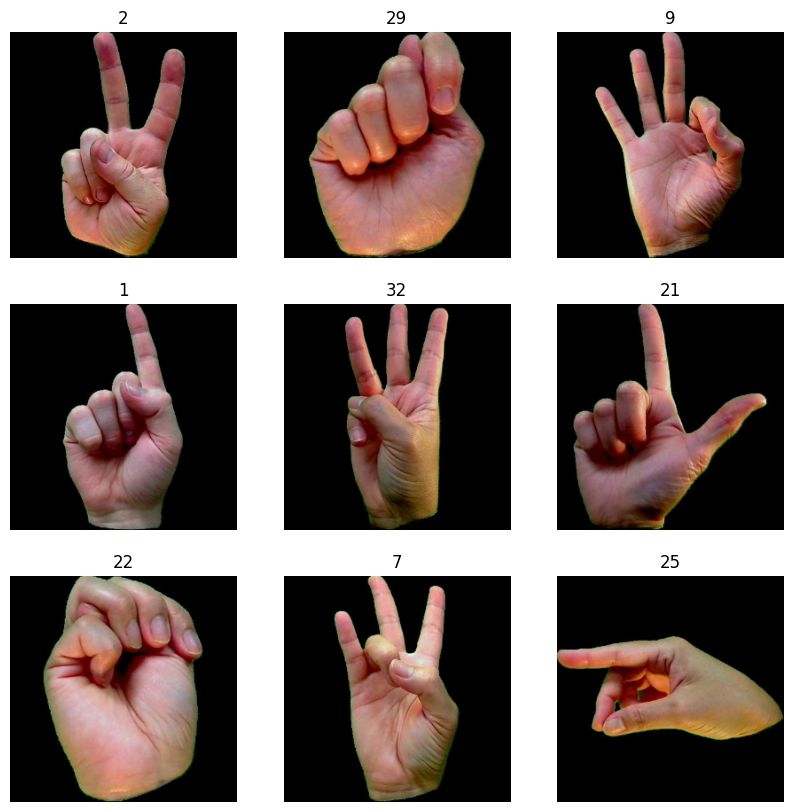

In [26]:
#Displaying image samples

plt.figure(figsize=(10, 10))
for images, labels in asl_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(int(labels[i]))
        plt.axis("off")

In [27]:
#Defining parameters for the loader

batch_size = 32
img_height = 64
img_width = 64

#Filtering out corrupted images

import os
num_skipped = 0
for folder_name in ("0","1","2","3","4","5","6","7","8","9","a","b","c","d","e","f","g","h","i","j","k","l","m","n","o"
                    ,"p","q","r","s","t","u","v","w","x","y","z"):
    folder_path = os.path.join(ds_asl_dir, folder_name)
    for fname in os.listdir(folder_path):
        fpath = os.path.join(folder_path, fname)
        try:
            fobj = open(fpath, "rb")
            is_jfif = tf.compat.as_bytes("JFIF") in fobj.peek(10)
        finally:
            fobj.close()
        if not is_jfif:
            num_skipped += 1
            # Delete corrupted image
            os.remove(fpath)
print("Deleted %d images" % num_skipped)

#Augmenting the images

from keras.preprocessing.image import ImageDataGenerator
data_augmentation = ImageDataGenerator(rotation_range=15, rescale=1/255, zoom_range=0.1, horizontal_flip=True,
                                       width_shift_range=0.1, height_shift_range=0.1, validation_split=0.2)

#Setting train/test split

asl_train_ds = data_augmentation.flow_from_directory(directory=ds_asl_dir, target_size=(img_height, img_width),
                                                     class_mode="categorical", batch_size=batch_size, subset="training")
asl_test_ds = data_augmentation.flow_from_directory(directory=ds_asl_dir, target_size=(img_height, img_width),
                                                    class_mode="categorical", batch_size=batch_size, subset="validation")

Deleted 0 images
Found 2012 images belonging to 36 classes.
Found 503 images belonging to 36 classes.


In [28]:
from keras.layers import Conv2D,MaxPool2D,Dropout,Flatten,Dense

#Checking if the data format i.e the RGB channel is coming first or last so, whatever it may be, model will check first and then input shape will be feeded accordingly.

from keras import backend as K
if K.image_data_format() == "channels_first":
    input_shape = (3, img_height, img_width)
else:
    input_shape = (img_height, img_width, 3)

#Creating a model

model_dl = keras.Sequential()
model_dl.add(Conv2D(16,(3,3),activation="relu",input_shape=(input_shape)))
model_dl.add(MaxPool2D(2,2))
model_dl.add(Dropout(0.2))
model_dl.add(Conv2D(32,(3,3),activation="relu"))
model_dl.add(MaxPool2D(2,2))
model_dl.add(Dropout(0.2))
model_dl.add(Conv2D(64,(3,3),activation="relu"))
model_dl.add(MaxPool2D(2,2))
model_dl.add(Dropout(0.2))
model_dl.add(Flatten())
model_dl.add(Dense(128,activation="relu"))
model_dl.add(Dropout(0.2))
model_dl.add(Dense(36,activation="softmax"))

In [29]:
#Compiling the neural network

model_dl.compile(optimizer="Adam", loss="categorical_crossentropy", metrics=["accuracy"])

#Fitting to the model

from keras.callbacks import EarlyStopping,ReduceLROnPlateau #Import callback functions
earlystop=EarlyStopping(patience=10) #Monitor the performance. If it dips, then stop training
learning_rate_reduce=ReduceLROnPlateau(monitor="val_acc",min_lr=0.001) #Change learning rate if not performing good enough
callbacks=[earlystop,learning_rate_reduce]

model_dl.fit(asl_train_ds, validation_data=asl_test_ds, callbacks=callbacks, epochs=40)

Epoch 1/40
63/63 [==============================] - 13s 165ms/step - loss: 3.5229 - accuracy: 0.0457 - val_loss: 3.2773 - val_accuracy: 0.1093 - lr: 0.0010
Epoch 2/40
63/63 [==============================] - 10s 158ms/step - loss: 2.8762 - accuracy: 0.1610 - val_loss: 2.4639 - val_accuracy: 0.2823 - lr: 0.0010
Epoch 3/40
63/63 [==============================] - 10s 154ms/step - loss: 2.2917 - accuracy: 0.2917 - val_loss: 1.8144 - val_accuracy: 0.4294 - lr: 0.0010
Epoch 4/40
63/63 [==============================] - 9s 148ms/step - loss: 1.9449 - accuracy: 0.3733 - val_loss: 1.5342 - val_accuracy: 0.4851 - lr: 0.0010
Epoch 5/40
63/63 [==============================] - 10s 151ms/step - loss: 1.6392 - accuracy: 0.4533 - val_loss: 1.3659 - val_accuracy: 0.5288 - lr: 0.0010
Epoch 6/40
63/63 [==============================] - 9s 148ms/step - loss: 1.4957 - accuracy: 0.5060 - val_loss: 1.2716 - val_accuracy: 0.5964 - lr: 0.0010
Epoch 7/40
63/63 [==============================] - 9s 147ms/step 

In [32]:
#Saving the model

model_dl.save("model_dl.h5")

#Loading the model

model_dl = keras.models.load_model("model_dl.h5") #look for local saved file

In [35]:
from tensorflow.keras.preprocessing import image as tf_image
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Assuming img_width and img_height are defined
img_width, img_height = 64, 64

# Creating a dictionary to map each of the indexes to the corresponding number or letter
my_dict = {0:"0", 1:"1", 2:"2", 3:"3", 4:"4", 5:"5", 6:"6", 7:"7", 8:"8", 9:"9", 10:"a", 11:"b", 12:"c", 13:"d", 14:"e", 15:"f", 16:"g",
           17:"h", 18:"i", 19:"j", 20:"k", 21:"l", 22:"m", 23:"n", 24:"o", 25:"p", 26:"q", 27:"r", 28:"s", 29:"t", 30:"u", 31:"v", 32:"w",
           33:"x", 34:"y", 35:"z"}

# Load your model
model_dl = load_model("model_dl.h5")  # Look for the local saved file

# Load and preprocess the image
img_path = "C:\\Users\\vishw\\Downloads\\archive (5)\\asl_dataset\\w\\hand2_w_top_seg_2_cropped.jpeg"
img = tf_image.load_img(img_path, target_size=(img_width, img_height))
x = tf_image.img_to_array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)  # Apply preprocessing specific to the model architecture

# Make predictions
predictions = model_dl.predict(x)
predicted_class_index = np.argmax(predictions, axis=1)

print(f'The predicted image corresponds to "{my_dict[predicted_class_index.item()]}" with {predictions[0][predicted_class_index.item()]*100:.2f}% probability.')


1/1 [==============================] - 0s 246ms/step
The predicted image corresponds to "9" with 99.91% probability.
